# M5.7 · Barra 风格归因

> 把组合收益分解到各风格因子（Size/Beta/Momentum 等）与特定收益上：
> 组合因子暴露 × 因子收益 = 因子贡献，剩余为特定（idiosyncratic）收益。

## 一、方法

1. 用 `build_barra` 构造风格暴露，并做**截面标准化**（减均值、除标准差），暴露量级约 1；
2. 逐期截面回归 $r_i=\alpha+\sum_k X_{ik}f_k+\epsilon_i$，得因子收益 $f_k$ 与残差；
3. 组合暴露 $=\sum_i w_i X_{ik}$，因子贡献 = 组合暴露 × 因子收益；
4. 国家（截距）+ 各风格 + 特定收益应等于组合实际收益，核对闭合。

## 二、数据与归因

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2.barra import build_barra
from bt_lab2 import style_attrib as sa
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
fields = ['$close', '$volume', '$mkt_cap_ard', '$pe_ttm', '$pb_lf']
raw = D.features(codes, fields, start_time='2018-01-01', freq='day')
tables = {f: raw[f].unstack('instrument') for f in fields}
n_sel, win = 30, 250; sub = codes[:n_sel]
barra_all = build_barra(tables['$close'], tables['$volume'], tables['$mkt_cap_ard'],
                        tables['$pe_ttm'], tables['$pb_lf'],
                        tables['$close'].pct_change(fill_method=None))
panels = {}
for k in ['Size', 'Beta', 'Momentum']:
    p = barra_all[k][sub].iloc[-win:]
    p = p.sub(p.mean(axis=1), axis=0).div(p.std(axis=1).replace(0, np.nan), axis=0)
    panels[k] = p.fillna(0)
cl = tables['$close'][sub].iloc[-win:]
returns = cl.pct_change(fill_method=None).fillna(0)
small10 = panels['Size'].iloc[0].nsmallest(10).index
weights = pd.DataFrame(0.0, index=returns.index, columns=returns.columns)
weights[small10] = 0.1
att = sa.style_attribution(weights, returns, panels)
print('闭合残差=%.2e' % att['closure_residual'])
print('期末累计贡献:'); print(att['cum_contrib'].iloc[-1].round(4))

[10116:MainThread](2026-11-05 15:24:06,559) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[10116:MainThread](2026-11-05 15:24:08,566) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[10116:MainThread](2026-11-05 15:24:08,568) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


闭合残差=-2.78e-17
期末累计贡献:
Country    -0.0486
Size       -0.1066
Beta       -0.0004
Momentum    0.0905
Specific    0.1062
Name: 2026-11-02 00:00:00, dtype: float64


## 三、可视化

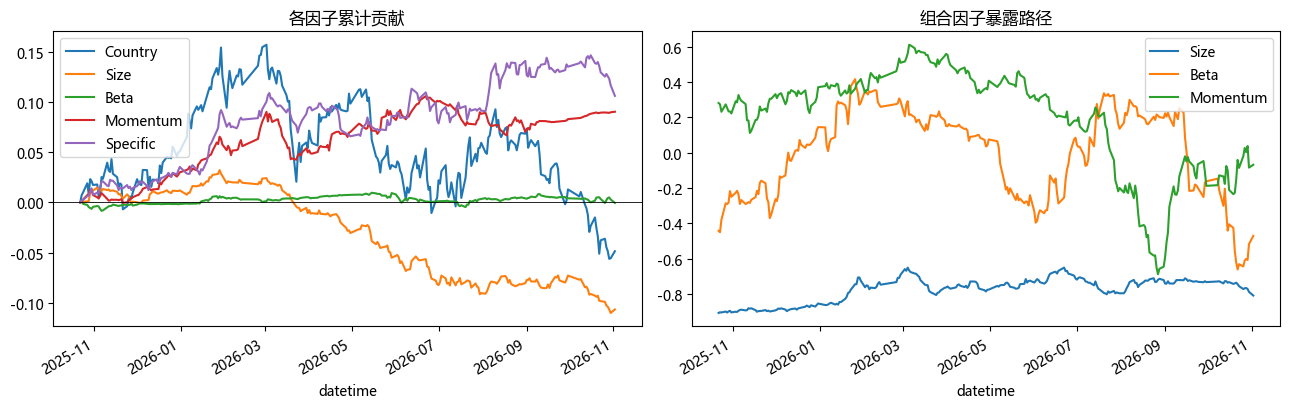

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
att['cum_contrib'].plot(ax=ax[0]); ax[0].set_title('各因子累计贡献'); ax[0].axhline(0, color='k', lw=0.6)
att['port_exposures'].plot(ax=ax[1]); ax[1].set_title('组合因子暴露路径')
plt.tight_layout(); plt.show()

## 四、面试要点

- **Barra 因子暴露为何要标准化？** 原始量纲（如 log 市值≈23）不可比且会放大贡献；标准化后暴露以标准差为单位、截面均值 0，可横向比较。
- **因子贡献如何计算？** 组合在因子上的暴露乘以该期因子收益；时间序列累计即该因子的总贡献。
- **特定收益是什么？** 因子模型无法解释的残差部分，反映个股选择带来的超额。
- **如何核对归因闭合？** 国家+各因子+特定的每期和应等于组合实际收益，残差接近 0 才可信。

## 五、练习

1. 增加 Residual Volatility、Liquidity 因子重新归因。
2. 换成等权组合，观察标准化后因子暴露为何接近 0。
3. 比较因子贡献在不同市场阶段的变化。
4. 用市值加权 WLS 替代 OLS 估计因子收益。